In [22]:
from mkt_yc_generator import *
from simple_derivatives_pricer import *
from vasicek_calibrator import vasicek_calibrator
import numpy as np
import matplotlib.pyplot as plt

## 1. Market Data and Calibration

We can either calibrate straight on the yields or price. In this work, we choose prices.

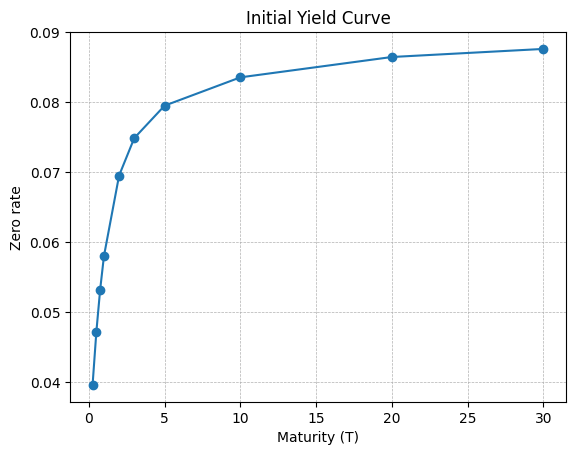

In [23]:
#====================================================
# Example initial market yield curve data
#====================================================
T_mkt = np.array([0.25, 0.5, 0.75, 1, 2, 3, 5, 10, 20, 30])
y_mkt = yield_curve(T_mkt)
price_mkt = np.exp(-y_mkt * T_mkt)  # Convert yields to prices

plt.figure()
plt.plot(T_mkt, y_mkt, marker='o')
plt.xlabel("Maturity (T)")
plt.ylabel("Zero rate")
plt.title("Initial Yield Curve")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

In [24]:
cal = vasicek_calibrator(T_mkt, price_mkt)
cal.calibrate()
cal.summary()


Calibrated Vasicek Parameters
-----------------------------------
Parameter            Value
-----------------------------------
a                 0.940268
b                 0.089189
sigma             0.000118
r0                0.042013
-----------------------------------
Objective     1.059086e-04


In [25]:
P_model = cal.vasicek_zcb_price(cal.params, cal.T_mkt)

print("\nMaturity | Market Price | Model Price")
print("--------------------------------------")

for T, pm, pmod in zip(cal.T_mkt, cal.price_mkt, P_model):
    print(f"{T:7.2f} | {pm:12.6f} | {pmod:11.6f}")


Maturity | Market Price | Model Price
--------------------------------------
   0.25 |     0.990136 |    0.988282
   0.50 |     0.976652 |    0.974554
   0.75 |     0.960842 |    0.959345
   1.00 |     0.943607 |    0.943075
   2.00 |     0.870126 |    0.872968
   3.00 |     0.798747 |    0.802212
   5.00 |     0.671885 |    0.672854
  10.00 |     0.433526 |    0.430968
  20.00 |     0.177330 |    0.176646
  30.00 |     0.072136 |    0.072404


## 2. Pricing Simple Derivatives

We use the market curve data

In [26]:
params = cal.calibrate()
a, b, sigma, r0 = params

T = 1 # choosen maturity
n_time, n_sim = 100, 10000

In [27]:
a, b, sigma, r0 

(0.940268231600671,
 0.08918905966437905,
 0.00011781081337833007,
 0.042012600891801)

### 2.1 Zero-Coupon Bonds

In [28]:
mc_price = zcb_price_mc_vasicek(r0, a, b, sigma, T, n_time, n_sim)
closed_price = cal.vasicek_zcb_price(cal.params, T)
#cn_price = zcb_price_cn_vasicek(r0, a, b, sigma, T, rmax=0.25)
cn_price = zcb_price_cn_vasicek(r0, a, b, sigma, T)

print("Method         | ZCB Price")
print("----------------|----------------")
print(f"MC              | {mc_price:.6f}")
print(f"Closed-form     | {closed_price:.6f}")
print(f"Crank-Nicolson  | {cn_price:.6f}")

Method         | ZCB Price
----------------|----------------
MC              | 0.943210
Closed-form     | 0.943075
Crank-Nicolson  | 0.941472


### 2.2 Forward-Rate Agreement

In [29]:
T1 = 0.5 * T
T2 = T
K = 0.07
fra_price = fra_price_vasicek(r0, a, b, sigma, T1, T2, K, N=1.0)
print("Method         | FRA Price")
print("----------------|----------------")
print(f"Analytical              | {fra_price:.6f}")

Method         | FRA Price
----------------|----------------
Analytical              | -0.001529


### 2.3 Interest Rate Swap

In [30]:
T = 2.5
Ts = [0.25*T, 0.5*T, 0.75*T, T]
K = 0.0843 #0.098413
irs_price = irs_price_vasicek(r0, a, b, sigma, Ts, K, N=1.0)
print("Method         | IRS Price")
print("----------------|----------------")
print(f"Analytical              | {irs_price:.6f}")

Method         | IRS Price
----------------|----------------
Analytical              | -0.023334


### 2.4 Par Swap Rate

In [31]:
Ts = [0.25*T, 0.5*T, 0.75*T, T]
K_star = par_swap_rate_vasicek(r0, a, b, sigma, Ts)
print("Method         | Par Swap Rate")
print("----------------|----------------")
print(f"Analytical              | {K_star:.6f}")

Method         | Par Swap Rate
----------------|----------------
Analytical              | 0.098413
